# Atividade 1 - Primeiro contato com PyTorch — Cat vs. Not Cat

## Objetivo
Construir uma rede neural simples para classificar imagens como gato ou não-gato.

O código não está pronto. Em cada etapa, você deverá desenvolver sua solução.

**Fluxo:** dados → rede neural → treinamento → resultado → uma alteração → comparação

### Dataset

O dataset desta atividade é o arquivo **`cat_not_cat.csv`**. Esse arquivo não possui cabeçalho. Cada linha representa uma imagem. As primeiras colunas contêm os valores dos pixels, e a última coluna contém o label da imagem.

O arquivo deve ficar na mesma pasta do notebook; caso contrário, ajuste o caminho no código.

> O objetivo desta atividade também é desenvolver sua autonomia na busca por conhecimento. Se você não souber como fazer algo, seja utilizar o GitHub, implementar uma etapa ou entender um conceito, pesquise e busque compreender antes de seguir. Faz parte da atividade aprender a encontrar as respostas.

> Você não precisa entender ainda toda a matemática do treinamento. Neste momento, o objetivo é aprender a usar o PyTorch e reconhecer as principais etapas.

## 0. Prepare sua branch no repositório

Antes de iniciar a atividade, acesse o repositório do projeto e crie uma branch própria para desenvolver e salvar seu exercício.

Repositório: https://github.com/LCCMat-UnB/segmentacao-laminas

Cada aluno deverá trabalhar em uma branch separada, sem alterar diretamente a branch main.

Use um nome que identifique claramente sua branch, por exemplo:

`atividade-1-seunome`

Não adicione o arquivo `cat_not_cat.csv` à sua branch. Faça o commit apenas do notebook e dos arquivos produzidos pela atividade.

Durante o desenvolvimento da atividade:

1. salve o notebook da atividade na sua branch;
2. faça commits ao longo do trabalho;
3. mantenha suas alterações apenas na sua branch;
4. ao finalizar a atividade, faça o último commit com a versão completa do notebook.

## 1. Conheça o dataset
Nesta etapa, você vai entender os dados antes de treinar o modelo.

Use as células de código abaixo para:
1. carregar o arquivo `cat_not_cat.csv`;
2. observar o formato de `X` e `y`;
3. visualizar algumas imagens.

### Responda
1. Quantos exemplos existem no dataset?
2. O que representa `X`?
3. O que representa `y`?
4. Quais são as duas classes?
5. Como uma imagem está representada nos dados?

In [23]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

csv_path = Path("cat_not_cat.csv")

# Carrega o CSV (sem cabeçalho)
df = pd.read_csv(csv_path, header=None)

# Separa os dados em entrada (X) e saída (y)
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].astype(int).values

# Use essas saídas para responder as perguntas da atividade
print("Formato de X:", X.shape)
print("Formato de y:", y.shape)
print("Valores únicos em y:", np.unique(y))
print("Primeiros 10 valores de X[0]:", X[0, :10])

Formato de X: (258, 12288)
Formato de y: (258,)
Valores únicos em y: [0 1]
Primeiros 10 valores de X[0]: [17. 31. 56. 22. 33. 59. 25. 35. 62. 25.]


### Respostas:

1 ) 258

2 ) O 'X' representa a quantidade de pixeis de cada imagem.

3 ) O 'Y' representa o que cada imagem é, no contexto, se é gato ou não gato.

4 ) O tamanho da imagem e quantas imagens existem no arquivo.

5 ) Cada imagem está sendo representada por uma matriz.

Label da imagem 0: 0
Primeiros 10 pixels da imagem 0: [17. 31. 56. 22. 33. 59. 25. 35. 62. 25.]


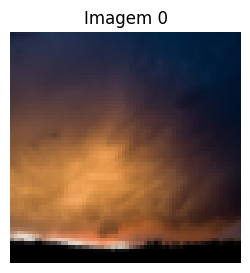

In [24]:
# Exemplo: olhando a primeira linha do CSV
print("Label da imagem 0:", y[0])
print("Primeiros 10 pixels da imagem 0:", X[0, :10])

# Para visualizar, reorganizamos os 12288 pixels para 64x64x3 (64x64x3=12288)
img0 = X[0].reshape(64, 64, 3).astype("uint8")
plt.figure(figsize=(3, 3))
plt.imshow(img0)
plt.title("Imagem 0")
plt.axis("off")
plt.show()

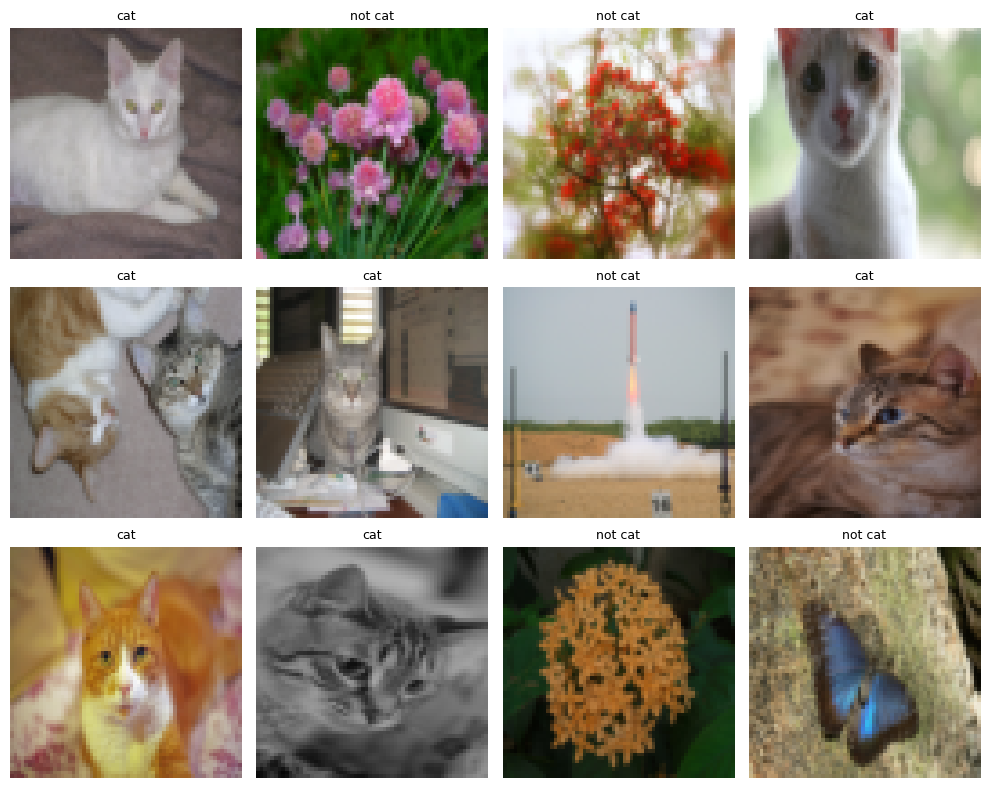

In [25]:
# Mostra 12 imagens aleatórias do dataset
n_images = 12
indices = np.random.default_rng(42).choice(len(X), size=n_images, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax, i in zip(axes.ravel(), indices):
    img = X[i].reshape(64, 64, 3).astype("uint8")
    label = "cat" if y[i] == 1 else "not cat"

    ax.imshow(img)
    ax.set_title(label, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2. Separe os dados em treino e teste
Agora que você já tem o dataset carregado em `X` e `y`, o próximo passo é separar em:
- **treino:** dados usados para o modelo aprender;
- **teste:** dados usados para verificar se o modelo generaliza.

Utilize `random_state=42` para tornar a divisão reproduzível e preserve a proporção das classes nos dois conjuntos.

### Responda
1. Qual proporção você escolheu e por que?
2. Qual é o sentido de separar os dados em treino e teste?
3. Por que não devemos avaliar o modelo somente nos dados usados no treinamento?

> Nesta atividade introdutória, utilizaremos o conjunto de teste para uma comparação simples. Em projetos reais, normalmente mantemos um conjunto de validação para escolher configurações e reservamos o teste para a avaliação final.

In [26]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## Respostas:

1. A proporção escolhida foi de 80% pra treino e 20% para teste.

2. Os dados de treino serão usados para a rede neural aprender o que gato ou não. Já os dados de teste serão usados para ver se a rede neural aprendeu corretamente.

3. Porque tem chance da rede neural ter só 'decorado' o que é gato ou não da base de dados de treino e, não ter aprendido o que realmente é gato ou não.

## 3. Prepare os dados

Antes de treinar o modelo, investigue como os valores dos pixels estão representados no dataset.

Verifique o menor e o maior valor encontrado e pesquise se é necessário realizar alguma transformação nesses valores antes de fornecê-los à rede neural.

Depois, transforme os dados para o formato utilizado pelo PyTorch.

Verifique também qual deve ser o tipo (`dtype`) dos tensores de entrada e dos labels para utilizar a `BCEWithLogitsLoss`.

### Responda
1. Qual é o menor e o maior valor dos pixels?
2. Foi necessário normalizar os dados? Por quê?
3. Qual transformação você realizou?
4. Por que escolheu essa transformação?
5. O que é um tensor?

In [27]:
#Normalização
X_treino = X_treino/255.0
X_teste = X_teste/255.0

tensor_X_treino = torch.tensor(X_treino, dtype=torch.float32)
tensor_y_treino = torch.tensor(y_treino, dtype=torch.float32).unsqueeze(1)

tensor_X_teste = torch.tensor(X_teste, dtype=torch.float32)
tensor_y_teste = torch.tensor(y_teste, dtype=torch.float32).unsqueeze(1)

## Respostas:

1. O menor valor foi de 0.0 e o maior valor foi de 255.0

2. Foi normalizado, porque a rede neural pode ter problema para ler números muito grandes, por isso todos os valores foram divididos por 255, que os valores finais ficaram entre 0 e 1.

3. Foi transformado so valores para float32 e transformou o tensor linha para um tensor coluna.

4. A primeira transformação foi feita porque o pytorch trabalha com float32 e não com float64. Já a segunda foi feita para manter as dimensões certas para a análise.

5. Tensor são as informações de cada imagem representadas em uma matriz numérica

## 4. Organize os dados para o treinamento
Use o **DataLoader** do PyTorch para organizar os dados de treino.

Para o baseline, utilize **batch size = 32**.

### Responda
1. O que é um DataLoader?
2. O que é um batch?
3. O que significa batch size = 32?
4. Por que embaralhamos os dados de treino?

In [28]:
dataset_treino = TensorDataset(tensor_X_treino, tensor_y_treino)
dataset_teste = TensorDataset(tensor_X_teste, tensor_y_teste)

treino_loader = DataLoader(dataset_treino, batch_size=32, shuffle=True)

## Respostas:

1. O DataLoader é uma forma de otimizar o código. Ele divide as imagens em lotes para passar na rede neural.

2. É um grupo de imagens que contém n imagens.

3. Significa que cada batch vai conter 32 imagens.

4. Para a rede neural não decorar as imagens, ou seja, para a rede neural aprender o que é gato ou não gato, e não somente decorar as imagens de treino.

## 5. Crie a rede neural

Crie uma rede neural simples:

**entrada → camada com 16 neurônios → ReLU → uma saída (logit)**

Como este é um problema binário (gato ou não-gato), use um neurônio de saída. Não inclua a função `sigmoid` na arquitetura do modelo. A `BCEWithLogitsLoss` já realiza essa operação internamente durante o cálculo da loss.

### Responda
1. Quantos valores entram na rede para cada exemplo?
2. Quantos neurônios existem na camada intermediária?
3. Qual função de ativação você utilizou?
4. Quantas saídas sua rede possui?
5. Por que você escolheu essa função de ativação?

In [29]:
class RedeNeural(nn.Module):
    def __init__(self, input_dim):
        super(RedeNeural, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
            )

    def forward(self, x):
        return self.network(x)

input_dim = X_treino.shape[1]
Rede = RedeNeural(input_dim)


## Respostas:

1. O valor de entrada é de 12.288 pixels.

2. Existem 16 neurônios

3. A função de ativação escolhida foi o 'nn.ReLU()'

4. A saída é de 1 neurônio

5. Porque ela permite a Rede Neural a aprender o que é gato em diversas posições, e não somente em uma posição.

## 6. Configure o treinamento

- **Loss:** `BCEWithLogitsLoss`;
- **Optimizer:** Adam;
- **Learning rate:** 0.001;
- **Epochs:** 10.

**Baseline** é o modelo inicial que será usado como referência.

Como este problema é binário, usamos 1 saída (logit) e `BCEWithLogitsLoss`, que já combina sigmoid + binary cross-entropy com melhor estabilidade numérica.

Dica prática: garanta que `y` esteja em `float32` e com o mesmo formato da saída do modelo (por exemplo, `[batch, 1]`).

### Responda

1. O que é a loss?
2. Por que `BCEWithLogitsLoss` é adequada neste caso?
3. O que o optimizer faz?
4. O que é o learning rate?
5. O que é uma epoch?

In [30]:
criterio = nn.BCEWithLogitsLoss()
otimizador = torch.optim.Adam(Rede.parameters(), lr=0.001)
epochs = 10

## Respostas:

1. É o valor de quanto as previsões da rede neural estão erradas.

2. Porque como o problema é binário (é gato ou não gato), a função BCEWithLogitsLoss calcula a loss e já faz a Sigmoid no final.

3. Ela le o valor do erro e ajusta a Rede Neural para ela errar menos.

4. É o tamanho do passo que o otimizador vai fazer.

5. É cada passagem completa de treinamento feita pela Rede Neural.

## 7. Treine o baseline
Implemente o treinamento.

O modelo deverá:
1. receber os dados;
2. fazer uma previsão;
3. calcular o erro;
4. aprender a partir desse erro.

Registre a **loss de cada epoch**.

### Responda
1. A loss diminuiu durante o treinamento?
2. O que isso indica?
3. Qual foi a loss final?

In [31]:
losses = []

for epoch in range(epochs):
    epoch_loss = 0.0
    for batch_X, batch_y in treino_loader:
        otimizador.zero_grad()

        saida = Rede(batch_X)

        loss = criterio(saida, batch_y)

        loss.backward()

        otimizador.step()

        epoch_loss += loss.item() * batch_X.size(0)
    epoch_loss /= len(treino_loader.dataset)
    losses.append(epoch_loss)
    print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss:.4f}")

Epoch 1/10, Loss: 0.7258
Epoch 2/10, Loss: 0.7262
Epoch 3/10, Loss: 0.6655
Epoch 4/10, Loss: 0.6299
Epoch 5/10, Loss: 0.5973
Epoch 6/10, Loss: 0.5707
Epoch 7/10, Loss: 0.5664
Epoch 8/10, Loss: 0.5469
Epoch 9/10, Loss: 0.5568
Epoch 10/10, Loss: 0.5430


## Respostas:

1. O valor da loss diminuiu.

2. Isso indica que a Rede Neural foi aprendendo o que é gato ou não gato.

3. A loss final foi de 0,5430.

## 8. Veja o resultado
Crie um gráfico da **loss ao longo das epochs** e calcule a **accuracy** nos dados de teste.

Como a saída do modelo é um logit, aplique `torch.sigmoid()` durante a avaliação para obter uma probabilidade. Considere valores maiores ou iguais a `0.5` como classe 1 e valores menores que `0.5` como classe 0.

### Registre
**Accuracy do baseline:**  
**Loss final do baseline:**  

### Responda
1. O que o gráfico da loss mostra?
2. Qual foi a accuracy?
3. O que significa, por exemplo, uma accuracy de 80%?

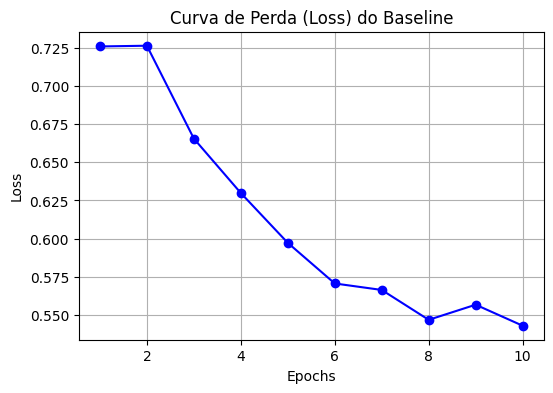

Acurácia do baseline no teste: 57.69%
Loss final do baseline: 0.5430


In [32]:
plt.figure(figsize = (6,4))
plt.plot(range(1, epochs + 1), losses, marker='o', color='blue')
plt.title("Curva de Perda (Loss) do Baseline")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

#Cálculo da acurácia

Rede.eval()
with torch.no_grad():
    saida_teste = Rede(tensor_X_teste)
    teste_prob = torch.round(torch.sigmoid(saida_teste))
    previsao = (teste_prob >= 0.5).float()

    previsao_certa = (previsao == tensor_y_teste).sum().item()
    acuracia = (previsao_certa / len(tensor_y_teste))*100

print(f"Acurácia do baseline no teste: {acuracia:.2f}%")
print(f"Loss final do baseline: {losses[-1]:.4f}")

## Respostas:

1. Mostra que a Rede Neural foi aprendendo o que é gato.

2. A accuracy foi de 57.69%.

3. Significa que de todas as imagens, a Rede Neural acertou em 80% das imagens o que ela se tratava (se é gato ou não gato).

## 9. Faça uma alteração

Escolha uma única característica do treinamento ou da rede para alterar. Pesquise uma possibilidade e explique por que decidiu testá-la.

Se precisar de ideias, você pode investigar alterações na quantidade de neurônios, learning rate, batch size ou número de epochs.

Crie e treine um novo modelo desde o início, mantendo a mesma divisão dos dados utilizada no baseline. Altere somente uma característica. Não continue o treinamento do modelo anterior.

Antes de testar, responda:

1. O que você vai alterar?
2. Por que escolheu isso?
3. O que você acha que vai acontecer?

## Repostas:

1. Eu irei alterar o valor da proporção de treino e teste para 60% para treino e 40% para teste.

2. Para saber se diminuir o que acontece quando diminui a proporção de treino e teste.

3. Pra 10% a menos de imagem de treino, talvez diminua a accuracy da rede Neural.

Epoch 1/10, Loss: 0.7238
Epoch 2/10, Loss: 0.6028
Epoch 3/10, Loss: 0.6033
Epoch 4/10, Loss: 0.5488
Epoch 5/10, Loss: 0.4777
Epoch 6/10, Loss: 0.4600
Epoch 7/10, Loss: 0.4363
Epoch 8/10, Loss: 0.4110
Epoch 9/10, Loss: 0.4093
Epoch 10/10, Loss: 0.3699


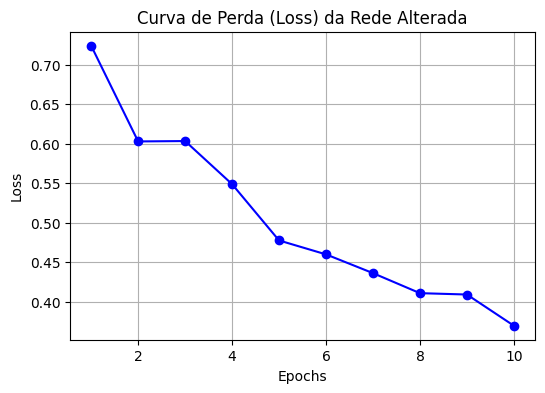

Acurácia do baseline no teste: 65.38%
Loss final do baseline: 0.3699


In [34]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

csv_path = Path("/content/drive/MyDrive/Projeto/cat_not_cat.csv")

# Carrega o CSV (sem cabeçalho)
df2 = pd.read_csv(csv_path, header=None)

# Separa os dados em entrada (X) e saída (y)
X2 = df2.iloc[:, :-1].values
y2 = df2.iloc[:, -1].astype(int).values

#2 - Separação dos dados

X2_treino, X2_teste, y2_treino, y2_teste = train_test_split(X2, y2, test_size=0.4, random_state=42, stratify=y2)


#3 - Preparação dos dados

#Normalização
X2_treino = X2_treino/255.0
X2_teste = X2_teste/255.0

tensor_X2_treino = torch.tensor(X2_treino, dtype=torch.float32)
tensor_y2_treino = torch.tensor(y2_treino, dtype=torch.float32).unsqueeze(1)

tensor_X2_teste = torch.tensor(X2_teste, dtype=torch.float32)
tensor_y2_teste = torch.tensor(y2_teste, dtype=torch.float32).unsqueeze(1)

#4 - Organize os dados

dataset_treino2 = TensorDataset(tensor_X2_treino, tensor_y2_treino)
dataset_teste2 = TensorDataset(tensor_X2_teste, tensor_y2_teste)

treino2_loader = DataLoader(dataset_treino2, batch_size=32, shuffle=True)
teste2_loader = DataLoader(dataset_teste2, batch_size=32, shuffle=False)

#5 - Criar a Rede neural

class RedeNeural2(nn.Module):
    def __init__(self, input_dim):
        super(RedeNeural2, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
            )

    def forward(self, x):
        return self.network(x)

input2_dim = X2_treino.shape[1]
Rede2 = RedeNeural2(input2_dim)

criterio2 = nn.BCEWithLogitsLoss()
otimizador2 = torch.optim.Adam(Rede2.parameters(), lr=0.001)
epochs = 10

#7 - Treinamento

losses2 = []

for epoch in range(epochs):
    epoch_loss2 = 0.0
    for batch_X2, batch_y2 in treino2_loader:
        otimizador2.zero_grad()

        saida2 = Rede2(batch_X2)

        loss2 = criterio2(saida2, batch_y2)

        loss2.backward()

        otimizador2.step()

        epoch_loss2 += loss2.item() * batch_X2.size(0)
    epoch_loss2 /= len(treino2_loader.dataset)
    losses2.append(epoch_loss2)
    print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss2:.4f}")

#8 - Resultado

plt.figure(figsize = (6,4))
plt.plot(range(1, epochs + 1), losses2, marker='o', color='blue')
plt.title("Curva de Perda (Loss) da Rede Alterada")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)
plt.show()


#Cálculo da acurácia

Rede2.eval()
with torch.no_grad():
    saida_teste2 = Rede2(tensor_X2_teste)
    teste2_prob = torch.round(torch.sigmoid(saida_teste2))
    previsao2 = (teste2_prob >= 0.5).float()

    previsao2_certa = (previsao2 == tensor_y2_teste).sum().item()
    acuracia2 = (previsao2_certa / len(tensor_y2_teste))*100

print(f"Acurácia do baseline no teste: {acuracia2:.2f}%")
print(f"Loss final do baseline: {losses2[-1]:.4f}")

## 10. Compare
Compare seu experimento com o baseline.

| | Baseline | Meu experimento |
|---|---|---|
| O que mudou? | Prop_teste= 20 | Prop_teste= 40 |
| Accuracy | 57.69 | 65.38 %|
| Loss final | 0.5430 |   0.3699|

### Responda
1. O que você mudou?
2. A accuracy aumentou ou diminuiu?
3. A loss mudou?
4. O que você observou?

## Respostas:

1. A proporção de imagens para teste aumentou de 20% para 40%.

2. A accuracy aumentou quase 10%.

3. Sim, a loss diminuiu.

4. Aumentando a quantidade de imagens para teste, percebe-se que como havia mais imagens para a Rede Neural testar, então a acurácia aumentou e que não teve uma perda muito significativa em diminuir 20% das imagens que eram para treino da Rede.